In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from astropy.nddata import Cutout2D
import numba

In [2]:
biasfits = fits.open('11072025/SP20250710230021.fits')
data_bias = biasfits[0].data
avg_bias = np.average(data_bias, axis = 0)
del biasfits
del data_bias

In [3]:
@numba.jit #вычитаем bias
def image_proc(data, bias):
    data_clear = np.zeros((5001, 1024, 1024))
    for i in range(len(data)):
        data_clear[i] = data[i] - bias
    return data_clear

In [104]:
WDS211935837_550 = fits.open('11072025/SP20250710224636.fits')
data5837_550 = WDS211935837_550[0].data 

In [105]:
data5837_550_clear = image_proc(data5837_550, avg_bias)
del data5837_550

In [110]:
# %load proc.py
from astropy.utils.iers import conf
conf.auto_max_age = None

from astroplan import Observer
from astropy.io import fits
import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, SkyCoord
from astropy.time import Time
from astropy.coordinates import ICRS
import numpy as np

data1 = fits.open('11072025/SP20250710224636.fits') #кадр со звездой

ra = data1[0].header['RAAPP']
dec = data1[0].header['DECAPP']
date = data1[0].header['DATE']

print(date)

coord_eq = SkyCoord(frame=ICRS, ra=float(ra), dec=float(dec), obstime=date, unit="deg")

longitude = data1[1].header['LONGITUD']
latitude = data1[1].header['LATITUDE']
loc = EarthLocation.from_geodetic(longitude,latitude)

utcoffset = 3*u.hour
time = Time(date)
#time = Time(date) + utcoffset

print(time)

coord_altaz = coord_eq.transform_to(AltAz(obstime=date, location=loc))
print(f"Altitude = {coord_altaz.alt:.2}")
print(f"Azimuth = {coord_altaz.az:.2}")
alt = coord_altaz.alt.value
KGO = Observer(location=loc, name="KGO")

parall = np.rad2deg(KGO.parallactic_angle(time, coord_eq)).value

print(parall)
print(alt)


2025-07-10T22:44:56
2025-07-10T22:44:56.000
Altitude = 7.4e+01 deg
Azimuth = 1.4e+01 deg
-160.9060553492595
74.26926708976389


In [107]:
scale = 0.02
eta = 132.9
rotate_angle = parall - alt + 90 + eta
OBJECT = WDS211935837_550[0].header['OBJECT']

In [108]:
OBJECT

'WDS21193+5837'

In [109]:
data5837_550_avg = np.average(data5837_550_clear, axis = 0)

In [119]:
# вырезаем нужную звезду
from photutils.detection import find_peaks
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import gaussian_filter
#ищем самые яркие писксели
mean, median, std = sigma_clipped_stats(data5837_550_avg, sigma=3.0)
data_smooth = gaussian_filter(data5837_550_avg, sigma=5.0)
peaks = find_peaks(data_smooth, threshold=median + 5 * std, box_size=100)
x_init = peaks['x_peak']
y_init = peaks['y_peak']
'''
threshold_factor = 12
max_iters = 300
iter_count = 0
mean, median, std = sigma_clipped_stats(data5837_550_avg, sigma=2)
while True:
    peaks = find_peaks(data5837_550_avg, threshold=median + threshold_factor * std, box_size=150)
    n_peaks = len(peaks['x_peak'])
    if n_peaks >= 2:
        x_init = peaks['x_peak']
        y_init = peaks['y_peak']
        print(f'threshold_factor = {threshold_factor}')
        break
    
    # уменьшаем коэффициент на 0.5 и повторяем
    threshold_factor -= 0.2
    iter_count += 1
    
    # предохранитель от бесконечного цикла
    if iter_count >= max_iters or threshold_factor <= 0:
        raise RuntimeError(
            f"Не удалось подобрать порог: итераций={iter_count}, "
            f"threshold_factor={threshold_factor:.1f}"
        )

'''
lim1 = np.sqrt((x_init[0]-x_init[1])**2+(y_init[0]-y_init[1])**2)/0.85
lim2 = np.sqrt((x_init[0]-x_init[1])**2+(y_init[0]-y_init[1])**2)/1# это половина расстояния между звездами
cut_mask_first, cut_mask_second = np.zeros_like(data5837_550_clear[0], dtype=bool), np.zeros_like(data5837_550_clear[0], dtype=bool)
cutout_first = Cutout2D(data5837_550_avg, (x_init[0], y_init[0]), (lim1, lim1)) # первая звезда
cutout_second = Cutout2D(data5837_550_avg, (x_init[1], y_init[1]), (lim2, lim2)) # вторая зведа
x_min_first, x_max_first = cutout_first.slices_original[0].start, cutout_first.slices_original[0].stop #границы x1
y_min_first, y_max_first = cutout_first.slices_original[1].start, cutout_first.slices_original[1].stop #границы y1

x_min_second, x_max_second = cutout_second.slices_original[0].start, cutout_second.slices_original[0].stop #границы x2
y_min_second, y_max_second = cutout_second.slices_original[1].start, cutout_second.slices_original[1].stop #границы y2

cut_mask_first[x_min_first:x_max_first, y_min_first:y_max_first],  cut_mask_second[x_min_second:x_max_second, y_min_second:y_max_second] = True, True # макси для умножения
cut_mask = cut_mask_first + cut_mask_second


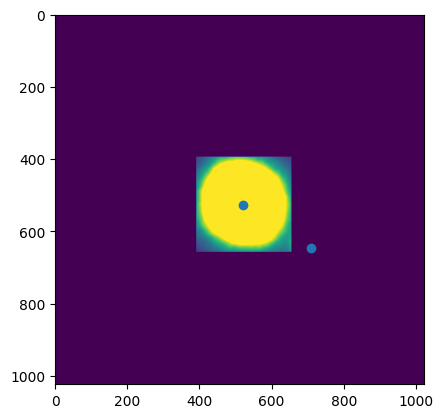

In [120]:
plt.imshow(data_smooth*cut_mask_first, vmin =0, vmax = 5)
plt.scatter(x_init, y_init)

In [121]:
def crop_nonzero_region(arr):

    if not np.any(arr):  # если все элементы нули
        return np.array([[]])  # или np.zeros((0, 0)) — на твой выбор

    nonzero_indices = np.argwhere(arr != 0)
    y_min, x_min = nonzero_indices.min(axis=0)
    y_max, x_max = nonzero_indices.max(axis=0) + 1  # включаем границы

    return arr[y_min:y_max, x_min:x_max]

In [122]:
data_cut = np.zeros_like(np.stack([cutout_first.data] * data5837_550_clear.shape[0]))
for i in range(len(data_cut)):
    data_cut[i] = crop_nonzero_region(data5837_550_clear[i]*cut_mask_first)

In [86]:
data_cut.shape

(5001, 61, 61)

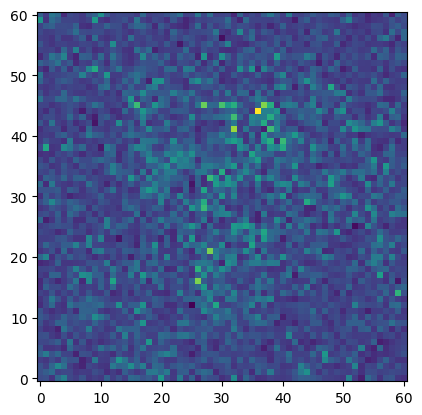

In [83]:
plt.imshow(data_cut[2266], origin = 'lower')

In [67]:
del data5837_550_clear

In [129]:
extent_result = np.array([-data_cut.shape[1]/2, data_cut.shape[1]/2, -data_cut.shape[2]/2, data_cut.shape[2]/2]) * scale #секунды

In [123]:
#усредняем серии кадров, центрируя по самому яркому пикселю
accum = np.zeros_like(data_cut[0], dtype = 'float')
for i in range(data_cut.shape[0]):
    img = data_cut[i]
    center = (data_cut.shape[1]//2, data_cut.shape[2]//2)
    
    y, x = np.unravel_index(np.argmax(img), img.shape)
    shift_y = center[0] - y
    shift_x = center[1] - x
    
    # сдвигаем и накапливаем
    img_shifted = np.roll(np.roll(img, shift_y, axis=0), shift_x, axis=1)
    accum += img_shifted
    
    # получаем окончательный результирующий образ
final_image = accum / data_cut.shape[0]

In [124]:
from scipy import ndimage
img_rot = ndimage.rotate(final_image, angle=-rotate_angle, reshape=True)
img_final = img_rot[:, ::-1]

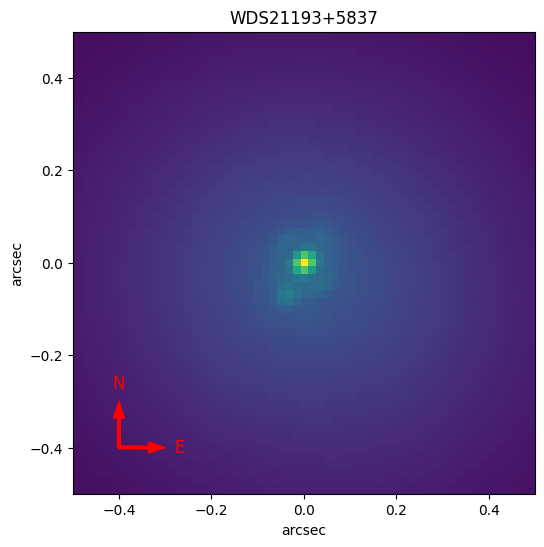

In [131]:
fig, ax = plt.subplots(figsize=(6, 6))

# Показываем ваше изображение
ax.imshow(np.abs(img_final),  extent=extent_result,  origin = 'lower')
ax.set_xlabel('arcsec')
ax.set_ylabel('arcsec')
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(-0.5, 0.5)
ax.set_title(OBJECT)

# Стрелка "Север" (красная)
ax.annotate(
    '', 
    xy=(0.1, 0.2),      # конец стрелки
    xytext=(0.1, 0.1),  # начало стрелки
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    0.1, 0.22, 'N',
    transform=ax.transAxes,
    ha='center', va='bottom',
    fontsize=12,
    color='red'
)

# Стрелка "Восток" (красная)
ax.annotate(
    '', 
    xy=(0.2, 0.1),      # конец стрелки
    xytext=(0.1, 0.1),  # начало стрелки
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    0.22, 0.1, 'E',
    transform=ax.transAxes,
    ha='left', va='center',
    fontsize=12,
    color='red'
)
plt.savefig('WDS_SAA.pdf',  bbox_inches="tight")



In [66]:
del data_cut